In [1]:
# Experiment 12 — Step 1: Environment setup

import sys
import platform
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
rng = np.random.default_rng(SEED)

print("Experiment 12: Cross-Condition Generalisation")
print("-" * 50)
print("Python:", platform.python_version())
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Working directory:", Path.cwd())
print("Random seed:", SEED)
print("Environment setup complete.")

Experiment 12: Cross-Condition Generalisation
--------------------------------------------------
Python: 3.13.16
NumPy: 2.1.3
Pandas: 2.2.3
Working directory: /content
Random seed: 42
Environment setup complete.


In [2]:
# Experiment 12 — Step 2: Inspect available project files
from pathlib import Path

search_roots = [
    Path("/content"),
    Path("/content/drive/MyDrive"),
]

extensions = {".npz", ".npy", ".csv", ".parquet", ".pkl"}

print("Searching for existing data and embedding files...\n")

seen = set()

for root in search_roots:
    if not root.exists():
        continue

    for path in root.rglob("*"):
        if not path.is_file() or path.suffix.lower() not in extensions:
            continue

        # Avoid duplicate paths
        resolved = str(path.resolve())
        if resolved in seen:
            continue
        seen.add(resolved)

        name = path.name.lower()
        if any(term in name for term in [
            "embedding", "experiment", "lfw", "drift", "feature"
        ]):
            print(f"{path}  ({path.stat().st_size:,} bytes)")

print("\nFile inspection complete.")

Searching for existing data and embedding files...


File inspection complete.


In [3]:
!git clone https://github.com/12998951/Real-Time-Embedding-Level-Drift-Detection.git /content/Real-Time-Embedding-Level-Drift-Detection

Cloning into '/content/Real-Time-Embedding-Level-Drift-Detection'...
remote: Enumerating objects: 305, done.
remote: Counting objects: 100% (75/75), done.
remote: Compressing objects: 100% (74/74), done.
remote: Total 305 (delta 28), reused 1 (delta 1), pack-reused 230 (from 1)
Receiving objects: 100% (305/305), 13.48 MiB | 4.82 MiB/s, done.
Resolving deltas: 100% (119/119), done.


In [4]:
from pathlib import Path

ROOT = Path("/content/Real-Time-Embedding-Level-Drift-Detection")

for path in sorted(ROOT.rglob("*")):
    if path.is_file() and path.suffix.lower() in {
        ".npz", ".npy", ".csv", ".parquet"
    }:
        print(path.relative_to(ROOT))

experiments/experiment10_50_direction_validation.csv
experiments/experiment10_combined_comparison.csv
experiments/experiment10_control_results.csv
experiments/experiment10_resampling_summary.csv
experiments/experiment10_resampling_trials.csv
experiments/experiment10_sensitivity_results.csv
experiments/experiment10_threshold_audit.csv
experiments/experiment10_threshold_stability_summary.csv
experiments/experiment10_threshold_stability_trials.csv
lfw_vit_embeddings.csv
results/LFW_Real_Data_Results/exp08_summary_results_v2.csv
results/LFW_Real_Data_Results/exp08_trial_results_v2.csv
results/LFW_Real_Data_Results/exp09_corrected_sensitivity_summary.csv
results/LFW_Real_Data_Results/exp09_trial_results.csv
results/LFW_Real_Data_Results/exp10_control_results.csv
results/LFW_Real_Data_Results/exp10_detection_summary.csv
results/LFW_Real_Data_Results/exp10_trial_results.csv
results/LFW_Real_Data_Results/lfw_independent_threshold_validation.csv
results/LFW_Real_Data_Results/lfw_repeated_seed_s

In [5]:
import pandas as pd
from pathlib import Path

path = Path(
    "/content/Real-Time-Embedding-Level-Drift-Detection/"
    "lfw_vit_embeddings.csv"
)

df = pd.read_csv(path, nrows=5)

print("Shape preview:", df.shape)
print("Columns:")
print(df.columns.tolist())
print("\nFirst 5 rows:")
display(df)

Shape preview: (5, 769)
Columns:
['0', '1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '20', '21', '22', '23', '24', '25', '26', '27', '28', '29', '30', '31', '32', '33', '34', '35', '36', '37', '38', '39', '40', '41', '42', '43', '44', '45', '46', '47', '48', '49', '50', '51', '52', '53', '54', '55', '56', '57', '58', '59', '60', '61', '62', '63', '64', '65', '66', '67', '68', '69', '70', '71', '72', '73', '74', '75', '76', '77', '78', '79', '80', '81', '82', '83', '84', '85', '86', '87', '88', '89', '90', '91', '92', '93', '94', '95', '96', '97', '98', '99', '100', '101', '102', '103', '104', '105', '106', '107', '108', '109', '110', '111', '112', '113', '114', '115', '116', '117', '118', '119', '120', '121', '122', '123', '124', '125', '126', '127', '128', '129', '130', '131', '132', '133', '134', '135', '136', '137', '138', '139', '140', '141', '142', '143', '144', '145', '146', '147', '148', '149', '150', '151', '152', '153'

,0,1,2,3,4,5,6,7,8,9,...,759,760,761,762,763,764,765,766,767,identity_label
0,1.445126,-0.275947,-2.486759,0.688646,-0.727520,-0.316534,2.009735,-0.029465,2.002846,0.024270,...,0.111501,-0.854688,-1.168884,1.235318,0.732669,1.168769,-0.381234,-1.591758,0.148663,61
1,0.894929,0.593413,-2.136880,1.322477,-0.087418,0.117707,1.572676,1.176135,0.072677,-0.490512,...,0.016100,1.377785,-0.721704,0.242011,0.141415,-0.591075,-0.856515,0.421215,-1.250429,25
2,-0.732671,0.638454,-1.932821,1.318641,0.374618,-0.311061,1.291052,1.322841,-0.089708,-0.238329,...,0.009332,0.510414,-1.693065,0.107993,0.322471,-0.644578,-0.168452,0.521841,-0.409709,9
3,0.142825,1.161895,-2.169970,0.441072,0.419739,-0.489438,0.471285,0.580722,-0.604124,-0.464962,...,-0.058881,0.875505,-0.338035,-0.046223,0.394094,-1.065154,0.004991,1.246743,-1.273321,5
4,-1.239340,-1.049585,-0.670516,0.793044,0.577204,0.194682,0.164315,1.630161,-1.108566,-1.350289,...,0.079717,-0.217188,-1.552062,0.734037,0.017011,-1.294054,0.182419,0.317357,-0.333472,1


In [7]:
from pathlib import Path
import pandas as pd

path = Path("/content/Real-Time-Embedding-Level-Drift-Detection/lfw_vit_embeddings.csv")
df = pd.read_csv(path)

X = df.drop(columns=["identity_label"]).to_numpy(dtype="float32")
y = df["identity_label"]

print("Dataset shape:", df.shape)
print("Embedding shape:", X.shape)
print("Unique identities:", y.nunique())
print("Missing values:", int(df.isna().sum().sum()))
print("Embedding values finite:", bool(__import__("numpy").isfinite(X).all()))
print("Images per identity (minimum):", int(y.value_counts().min()))
print("Images per identity (median):", float(y.value_counts().median()))
print("Images per identity (maximum):", int(y.value_counts().max()))

Dataset shape: (3023, 769)
Embedding shape: (3023, 768)
Unique identities: 62
Missing values: 0
Embedding values finite: True
Images per identity (minimum): 20
Images per identity (median): 31.0
Images per identity (maximum): 530


In [8]:
from pathlib import Path

root = Path("/content/Real-Time-Embedding-Level-Drift-Detection")

for name in ["README.md"]:
    p = root / name
    if p.exists():
        print(p.read_text()[:12000])

print("\nRelevant experiment files:")
for p in sorted((root / "experiments").glob("*")):
    if p.is_file() and p.suffix.lower() in {".py", ".ipynb", ".md"}:
        print(p.relative_to(root))

Real-Time Embedding-Level Drift Detection for Trustworthy Biometric Systems

A research project investigating label-free distributional drift detection in embedding spaces, with the long-term goal of improving the reliability and trustworthiness of biometric identification systems under changing operating conditions.

Current status: Synthetic-data prototype with preliminary evaluation. Validation using real biometric embeddings remains future work.

## Overview

Machine learning systems can encounter changes in their input data after deployment. In biometric applications, these changes may arise from variations in illumination, ageing, camera or microphone characteristics, environmental noise, and other operating conditions.

Such changes can alter the feature representations produced by face or voice encoders. Monitoring these representations may provide an early indication that the data distribution has changed, even when ground-truth labels or recognition accuracy measurements are 

In [18]:
from pathlib import Path
import json

p = Path("/content/Real-Time-Embedding-Level-Drift-Detection/experiments/11_Illumination_Drift_Detection.ipynb")
nb = json.loads(p.read_text())

print("Experiment 11 notebook found.")
print("Total cells:", len(nb["cells"]))

for i, cell in enumerate(nb["cells"]):
    if cell["cell_type"] == "markdown":
        text = "".join(cell["source"])
        if text.strip():
            print(f"\n--- Markdown cell {i} ---")
            print(text[:1200])

Experiment 11 notebook found.
Total cells: 27


In [19]:
for i, cell in enumerate(nb["cells"]):
    if cell["cell_type"] == "code":
        source = "".join(cell["source"])
        if source.strip():
            print(f"\n--- Code cell {i} ---")
            print(source[:1500])


--- Code cell 0 ---
# Experiment 11: Illumination Drift Detection
# Fresh setup — separate from Experiment 10

import os
import sys
import random
import platform
import json
import hashlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

PROJECT_DIR = Path("/content/Experiment_11")
DATA_DIR = PROJECT_DIR / "data"
RESULTS_DIR = PROJECT_DIR / "results"
FIGURES_DIR = PROJECT_DIR / "figures"

for directory in [DATA_DIR, RESULTS_DIR, FIGURES_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

print("Experiment 11 setup complete.")
print("Python:", sys.version.split()[0])
print("Platform:", platform.platform())
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Project directory:", PROJECT_DIR)

--- Code cell 1 ---
# Experiment 11: Install required libraries

%pip install -q torch torchvision scikit-learn scikit-image pillow tqdm

--- Code cell 2 ---
import torch
impor

In [20]:
from pathlib import Path

root = Path("/content/Real-Time-Embedding-Level-Drift-Detection/experiments")

for name in [
    "06_LFW_Real_Data_Drift_Validation.ipynb",
    "08_LFW_Robust_Drift_Detection_Evaluation.ipynb",
    "10_Improved_Drift_Evaluation_Methodology.ipynb"
]:
    path = root / name
    print(f"\n{name}: {'FOUND' if path.exists() else 'NOT FOUND'}")


06_LFW_Real_Data_Drift_Validation.ipynb: FOUND

08_LFW_Robust_Drift_Detection_Evaluation.ipynb: FOUND

10_Improved_Drift_Evaluation_Methodology.ipynb: FOUND


In [21]:
from pathlib import Path
import json

root = Path("/content/Real-Time-Embedding-Level-Drift-Detection/experiments")

for name in [
    "06_LFW_Real_Data_Drift_Validation.ipynb",
    "08_LFW_Robust_Drift_Detection_Evaluation.ipynb",
    "10_Improved_Drift_Evaluation_Methodology.ipynb"
]:
    nb = json.loads((root / name).read_text())
    print(f"\n{'=' * 65}\n{name}")

    for cell in nb["cells"]:
        if cell["cell_type"] == "markdown":
            text = "".join(cell["source"]).strip()
            if text.startswith("#"):
                print(text[:300].replace("\n", " "))


06_LFW_Real_Data_Drift_Validation.ipynb

08_LFW_Robust_Drift_Detection_Evaluation.ipynb

10_Improved_Drift_Evaluation_Methodology.ipynb


In [22]:
from pathlib import Path
import json

root = Path("/content/Real-Time-Embedding-Level-Drift-Detection/experiments")

for name in [
    "06_LFW_Real_Data_Drift_Validation.ipynb",
    "08_LFW_Robust_Drift_Detection_Evaluation.ipynb",
    "10_Improved_Drift_Evaluation_Methodology.ipynb"
]:
    nb = json.loads((root / name).read_text())
    print(f"\n{'=' * 60}\n{name}")

    shown = 0
    for i, cell in enumerate(nb["cells"]):
        if cell["cell_type"] == "code":
            source = "".join(cell["source"]).strip()
            if source:
                print(f"\nCell {i}:\n{source[:900]}")
                shown += 1
                if shown == 2:
                    break


06_LFW_Real_Data_Drift_Validation.ipynb

Cell 0:
%pip install -q numpy pandas scikit-learn matplotlib seaborn

Cell 1:
import sys
import numpy as np
import pandas as pd
import sklearn
import matplotlib

print("Python:", sys.version)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Matplotlib:", matplotlib.__version__)

08_LFW_Robust_Drift_Detection_Evaluation.ipynb

Cell 0:
# Experiment 08: Robust Drift Detection Evaluation
# Reproducible environment and configuration

import os
import random
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 2026
random.seed(SEED)
np.random.seed(SEED)

print("Experiment 08: Robust Drift Detection Evaluation")
print("-" * 55)
print("Python version:", platform.python_version())
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)
print("Random seed:", SEED)
print("Working directory:", os.getcwd())

# Planned experim

In [23]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

path = "/content/Real-Time-Embedding-Level-Drift-Detection/lfw_vit_embeddings.csv"
df = pd.read_csv(path)

feature_cols = [c for c in df.columns if c != "identity_label"]
X = df[feature_cols].to_numpy(dtype=np.float32)
y = df["identity_label"].to_numpy()

identities = np.unique(y)

ref_ids, remaining_ids = train_test_split(
    identities, test_size=0.4, random_state=42
)
cal_ids, eval_ids = train_test_split(
    remaining_ids, test_size=0.5, random_state=42
)

ref_mask = np.isin(y, ref_ids)
cal_mask = np.isin(y, cal_ids)
eval_mask = np.isin(y, eval_ids)

X_ref, X_cal, X_eval = X[ref_mask], X[cal_mask], X[eval_mask]

assert set(ref_ids).isdisjoint(cal_ids)
assert set(ref_ids).isdisjoint(eval_ids)
assert set(cal_ids).isdisjoint(eval_ids)

print("Reference:", X_ref.shape, "identities:", len(ref_ids))
print("Calibration:", X_cal.shape, "identities:", len(cal_ids))
print("Evaluation:", X_eval.shape, "identities:", len(eval_ids))
print("Identity-disjoint checks passed.")

Reference: (2101, 768) identities: 37
Calibration: (523, 768) identities: 12
Evaluation: (399, 768) identities: 13
Identity-disjoint checks passed.


In [24]:
import numpy as np

SEED = 42
WINDOW_SIZE = 20
rng = np.random.default_rng(SEED)

# Fit scaling on reference data only
feature_mean = X_ref.mean(axis=0)
feature_std = X_ref.std(axis=0)
feature_std[feature_std < 1e-8] = 1.0

def standardize(X):
    return (X - feature_mean) / feature_std

Z_ref = standardize(X_ref)
Z_cal = standardize(X_cal)

reference_centroid = Z_ref.mean(axis=0)

def window_scores(X, window_size=WINDOW_SIZE):
    n = len(X) // window_size
    windows = X[:n * window_size].reshape(
        n, window_size, X.shape[1]
    )
    means = windows.mean(axis=1)
    return np.linalg.norm(
        means - reference_centroid, axis=1
    )

calibration_scores = window_scores(Z_cal)
threshold = float(np.quantile(calibration_scores, 0.95, method="higher"))

print("Calibration windows:", len(calibration_scores))
print("Calibration threshold (95th percentile):", round(threshold, 6))
print("Reference dimensions:", Z_ref.shape[1])
print("Threshold fixed for subsequent evaluation.")

Calibration windows: 26
Calibration threshold (95th percentile): 8.449199
Reference dimensions: 768
Threshold fixed for subsequent evaluation.


In [25]:
import numpy as np
import pandas as pd

DRIFT_STRENGTHS = [0.00, 0.05, 0.10, 0.20, 0.35]
N_TRIALS = 30
WINDOW_SIZE = 20

rng = np.random.default_rng(202612)
Z_eval = standardize(X_eval)

results = []

for strength in DRIFT_STRENGTHS:
    for trial in range(N_TRIALS):
        shuffled = Z_eval[rng.permutation(len(Z_eval))]
        n_windows = len(shuffled) // WINDOW_SIZE
        windows = shuffled[:n_windows * WINDOW_SIZE].reshape(
            n_windows, WINDOW_SIZE, shuffled.shape[1]
        )

        shifted_windows = windows.copy()
        if strength > 0:
            shifted_windows += rng.normal(
                loc=strength,
                scale=0.0,
                size=shifted_windows.shape
            )

        scores = np.linalg.norm(
            shifted_windows.mean(axis=1) - reference_centroid,
            axis=1
        )

        results.append({
            "drift_strength": strength,
            "trial": trial + 1,
            "n_windows": len(scores),
            "detection_rate_percent": 100 * np.mean(scores > threshold),
            "mean_score": float(scores.mean())
        })

results_df = pd.DataFrame(results)
summary = results_df.groupby("drift_strength").agg(
    mean_detection_rate_percent=("detection_rate_percent", "mean"),
    std_detection_rate_percent=("detection_rate_percent", "std"),
    mean_score=("mean_score", "mean")
).reset_index()

display(summary.round(3))

,drift_strength,mean_detection_rate_percent,std_detection_rate_percent,mean_score
0,0.00,16.316,8.218,7.545
1,0.05,19.825,8.924,7.719
2,0.10,30.000,7.202,8.063
3,0.20,91.754,5.296,9.408
4,0.35,100.000,0.000,12.310


In [26]:
print("Current drift strengths:", DRIFT_STRENGTHS)
print("Current results shape:", results_df.shape)
print(results_df.groupby("drift_strength")["mean_score"].mean())

Current drift strengths: [0.0, 0.05, 0.1, 0.2, 0.35]
Current results shape: (150, 5)
drift_strength
0.00     7.545473
0.05     7.719182
0.10     8.062640
0.20     9.407871
0.35    12.310127
Name: mean_score, dtype: float64


In [27]:
import numpy as np
import pandas as pd

rng = np.random.default_rng(202612)
Z_eval = standardize(X_eval)
results = []

for strength in DRIFT_STRENGTHS:
    for trial in range(N_TRIALS):
        shuffled = Z_eval[rng.permutation(len(Z_eval))]
        n_windows = len(shuffled) // WINDOW_SIZE
        windows = shuffled[:n_windows * WINDOW_SIZE].reshape(
            n_windows, WINDOW_SIZE, Z_eval.shape[1]
        )

        direction = rng.normal(size=Z_eval.shape[1])
        direction /= np.linalg.norm(direction)
        shifted_windows = windows + strength * direction

        scores = np.linalg.norm(
            shifted_windows.mean(axis=1) - reference_centroid,
            axis=1
        )

        results.append({
            "drift_strength": strength,
            "trial": trial + 1,
            "detection_rate_percent": 100 * np.mean(scores > threshold),
            "mean_score": float(scores.mean())
        })

results_df = pd.DataFrame(results)

summary = results_df.groupby("drift_strength").agg(
    mean_detection_rate_percent=("detection_rate_percent", "mean"),
    std_detection_rate_percent=("detection_rate_percent", "std"),
    mean_score=("mean_score", "mean")
).reset_index()

print("Corrected evaluation completed.")
display(summary.round(3))

Corrected evaluation completed.


,drift_strength,mean_detection_rate_percent,std_detection_rate_percent,mean_score
0,0.00,17.018,7.902,7.607
1,0.05,20.351,6.874,7.602
2,0.10,17.368,7.202,7.579
3,0.20,19.298,5.918,7.605
4,0.35,17.368,7.589,7.592


In [28]:
import numpy as np
import pandas as pd

baseline_scores = []

for trial in range(30):
    shuffled = Z_eval[rng.permutation(len(Z_eval))]
    n = len(shuffled) // WINDOW_SIZE
    windows = shuffled[:n * WINDOW_SIZE].reshape(
        n, WINDOW_SIZE, Z_eval.shape[1]
    )
    scores = np.linalg.norm(
        windows.mean(axis=1) - reference_centroid, axis=1
    )
    baseline_scores.extend(scores)

baseline_scores = np.asarray(baseline_scores)

print("Fixed threshold:", round(threshold, 4))
print("Baseline mean score:", round(baseline_scores.mean(), 4))
print("Baseline score standard deviation:", round(baseline_scores.std(), 4))
print("Baseline alarm rate (%):", round(100 * np.mean(baseline_scores > threshold), 2))
print("Applied shift magnitudes:", DRIFT_STRENGTHS)
print("Maximum applied L2 shift:", max(DRIFT_STRENGTHS))

Fixed threshold: 8.4492
Baseline mean score: 7.594
Baseline score standard deviation: 1.0202
Baseline alarm rate (%): 18.6
Applied shift magnitudes: [0.0, 0.05, 0.1, 0.2, 0.35]
Maximum applied L2 shift: 0.35


In [29]:
import numpy as np
import pandas as pd

calibration_scores = np.asarray(calibration_scores)
baseline_scores = np.asarray(baseline_scores)

comparison = pd.DataFrame([
    {
        "dataset": "Calibration",
        "windows": len(calibration_scores),
        "mean_score": calibration_scores.mean(),
        "std_score": calibration_scores.std(),
        "threshold": threshold,
        "alarm_rate_percent": 100 * np.mean(calibration_scores > threshold),
    },
    {
        "dataset": "Evaluation baseline",
        "windows": len(baseline_scores),
        "mean_score": baseline_scores.mean(),
        "std_score": baseline_scores.std(),
        "threshold": threshold,
        "alarm_rate_percent": 100 * np.mean(baseline_scores > threshold),
    },
])

display(comparison.round(4))

,dataset,windows,mean_score,std_score,threshold,alarm_rate_percent
0,Calibration,26,7.2191,0.7017,8.4492,3.8462
1,Evaluation baseline,570,7.5940,1.0202,8.4492,18.5965


In [30]:
import numpy as np
import pandas as pd

WINDOW_SIZE = 20
Z_eval = standardize(X_eval)

n_windows = len(Z_eval) // WINDOW_SIZE
windowed_eval = Z_eval[:n_windows * WINDOW_SIZE].reshape(
    n_windows, WINDOW_SIZE, Z_eval.shape[1]
)

window_scores = np.linalg.norm(
    windowed_eval.mean(axis=1) - reference_centroid,
    axis=1
)

window_identity_counts = []
y_eval = y[eval_mask][:n_windows * WINDOW_SIZE].reshape(
    n_windows, WINDOW_SIZE
)

for i, labels_in_window in enumerate(y_eval):
    window_identity_counts.append({
        "window": i,
        "unique_identities": len(np.unique(labels_in_window)),
        "score": float(window_scores[i]),
        "alarm": bool(window_scores[i] > threshold)
    })

window_audit = pd.DataFrame(window_identity_counts)

print("Evaluation windows:", len(window_audit))
print("Mean unique identities per window:",
      round(window_audit["unique_identities"].mean(), 2))
print("Mean score:", round(window_audit["score"].mean(), 4))
print("Alarm rate (%):", round(100 * window_audit["alarm"].mean(), 2))

display(window_audit.head(10))

Evaluation windows: 19
Mean unique identities per window: 10.47
Mean score: 7.4168
Alarm rate (%): 10.53


,window,unique_identities,score,alarm
0,0,10,6.011847,False
1,1,12,6.694754,False
2,2,11,9.621014,True
3,3,11,7.391946,False
4,4,9,7.184671,False
5,5,10,8.054435,False
6,6,10,6.458693,False
7,7,10,7.636220,False
8,8,10,7.536873,False
9,9,11,7.186092,False


In [31]:
import numpy as np
import pandas as pd

WINDOW_SIZE = 20
Z_eval = standardize(X_eval)

n_windows = len(Z_eval) // WINDOW_SIZE
windows = Z_eval[:n_windows * WINDOW_SIZE].reshape(
    n_windows, WINDOW_SIZE, Z_eval.shape[1]
)

scores = np.linalg.norm(
    windows.mean(axis=1) - reference_centroid,
    axis=1
)
alarms = scores > threshold

print("Evaluation samples:", len(Z_eval))
print("Window size:", WINDOW_SIZE)
print("Complete evaluation windows:", n_windows)
print("Threshold:", round(threshold, 4))
print("Alarms:", int(alarms.sum()))
print("Alarm rate (%):", round(100 * alarms.mean(), 2))

Evaluation samples: 399
Window size: 20
Complete evaluation windows: 19
Threshold: 8.4492
Alarms: 2
Alarm rate (%): 10.53


In [32]:
import pandas as pd
import numpy as np

identity_audit = window_audit.copy()

identity_audit["identity_group"] = pd.cut(
    identity_audit["unique_identities"],
    bins=[0, 8, 10, 12, 100],
    labels=["1–8", "9–10", "11–12", "13+"],
    include_lowest=True
)

summary = identity_audit.groupby(
    "identity_group", observed=False
).agg(
    windows=("score", "size"),
    mean_score=("score", "mean"),
    alarm_rate_percent=("alarm", lambda x: 100 * x.mean())
).reset_index()

display(summary.round(3))

,identity_group,windows,mean_score,alarm_rate_percent
0,1–8,0,NaN,NaN
1,9–10,11,7.465,9.091
2,11–12,7,7.425,14.286
3,13+,1,6.826,0.000


In [33]:
import numpy as np
import pandas as pd

WINDOW_SIZE = 20
DRIFT_STRENGTHS = [0.0, 0.5, 1.0, 2.0, 4.0]

Z_eval = standardize(X_eval)
n_windows = len(Z_eval) // WINDOW_SIZE

windows = Z_eval[:n_windows * WINDOW_SIZE].reshape(
    n_windows, WINDOW_SIZE, Z_eval.shape[1]
)

direction_rng = np.random.default_rng(202612)
direction = direction_rng.normal(size=Z_eval.shape[1])
direction /= np.linalg.norm(direction)

rows = []

for strength in DRIFT_STRENGTHS:
    shifted = windows + strength * direction
    scores = np.linalg.norm(
        shifted.mean(axis=1) - reference_centroid,
        axis=1
    )

    rows.append({
        "shift_strength_L2": strength,
        "mean_score": scores.mean(),
        "alarm_count": int(np.sum(scores > threshold)),
        "alarm_rate_percent": 100 * np.mean(scores > threshold)
    })

shift_sensitivity = pd.DataFrame(rows)
display(shift_sensitivity.round(3))

,shift_strength_L2,mean_score,alarm_count,alarm_rate_percent
0,0.0,7.417,2,10.526
1,0.5,7.427,2,10.526
2,1.0,7.471,2,10.526
3,2.0,7.659,2,10.526
4,4.0,8.389,7,36.842


In [34]:
import numpy as np
import pandas as pd

WINDOW_SIZE = 20
DRIFT_STRENGTHS = [0.0, 1.0, 2.0, 4.0]
N_DIRECTIONS = 30

Z_eval = standardize(X_eval)
n_windows = len(Z_eval) // WINDOW_SIZE

windows = Z_eval[:n_windows * WINDOW_SIZE].reshape(
    n_windows, WINDOW_SIZE, Z_eval.shape[1]
)

rng = np.random.default_rng(202613)
rows = []

for strength in DRIFT_STRENGTHS:
    for direction_id in range(N_DIRECTIONS):
        direction = rng.normal(size=Z_eval.shape[1])
        direction /= np.linalg.norm(direction)

        shifted = windows + strength * direction
        scores = np.linalg.norm(
            shifted.mean(axis=1) - reference_centroid,
            axis=1
        )

        rows.append({
            "shift_strength_L2": strength,
            "direction": direction_id + 1,
            "alarm_rate_percent": 100 * np.mean(scores > threshold),
            "mean_score": scores.mean()
        })

direction_results = pd.DataFrame(rows)

summary = direction_results.groupby("shift_strength_L2").agg(
    mean_alarm_rate=("alarm_rate_percent", "mean"),
    std_alarm_rate=("alarm_rate_percent", "std"),
    mean_score=("mean_score", "mean")
).reset_index()

display(summary.round(3))

,shift_strength_L2,mean_alarm_rate,std_alarm_rate,mean_score
0,0.0,10.526,0.000,7.417
1,1.0,10.526,0.000,7.483
2,2.0,11.579,2.141,7.691
3,4.0,42.807,4.085,8.436


In [35]:
import numpy as np
import pandas as pd

cal_scores = np.asarray(calibration_scores)

calibration_audit = pd.DataFrame({
    "statistic": [
        "Number of calibration windows",
        "Minimum score",
        "25th percentile",
        "Median score",
        "95th percentile",
        "Maximum score",
        "Fixed threshold",
        "Observed calibration alarm rate (%)"
    ],
    "value": [
        len(cal_scores),
        np.min(cal_scores),
        np.quantile(cal_scores, 0.25),
        np.median(cal_scores),
        np.quantile(cal_scores, 0.95),
        np.max(cal_scores),
        threshold,
        100 * np.mean(cal_scores > threshold)
    ]
})

display(calibration_audit.round(4))

,statistic,value
0,Number of calibration windows,26.0000
1,Minimum score,6.1532
2,25th percentile,6.6715
3,Median score,7.2072
4,95th percentile,8.3620
5,Maximum score,9.3047
6,Fixed threshold,8.4492
7,Observed calibration alarm rate (%),3.8462


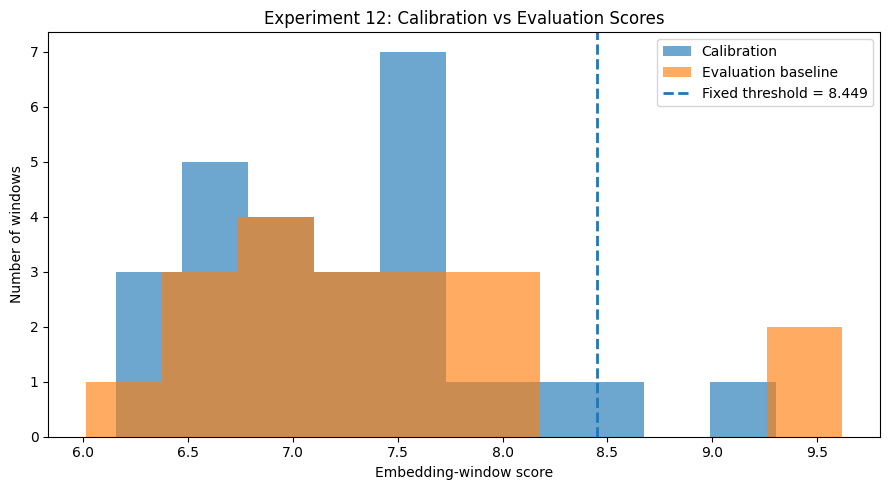

In [36]:
import matplotlib.pyplot as plt
import numpy as np

cal_scores = np.asarray(calibration_scores)

Z_eval = standardize(X_eval)
n_windows = len(Z_eval) // WINDOW_SIZE

eval_windows = Z_eval[:n_windows * WINDOW_SIZE].reshape(
    n_windows, WINDOW_SIZE, Z_eval.shape[1]
)

eval_scores = np.linalg.norm(
    eval_windows.mean(axis=1) - reference_centroid,
    axis=1
)

plt.figure(figsize=(9, 5))
plt.hist(cal_scores, bins=10, alpha=0.65, label="Calibration")
plt.hist(eval_scores, bins=10, alpha=0.65, label="Evaluation baseline")
plt.axvline(
    threshold,
    linestyle="--",
    linewidth=2,
    label=f"Fixed threshold = {threshold:.3f}"
)
plt.xlabel("Embedding-window score")
plt.ylabel("Number of windows")
plt.title("Experiment 12: Calibration vs Evaluation Scores")
plt.legend()
plt.tight_layout()
plt.show()

In [37]:
import pandas as pd
import numpy as np

baseline_results = pd.DataFrame([{
    "experiment": "Experiment 12",
    "calibration_windows": len(calibration_scores),
    "evaluation_windows": len(eval_scores),
    "threshold": threshold,
    "calibration_alarm_rate_percent":
        100 * np.mean(np.asarray(calibration_scores) > threshold),
    "evaluation_baseline_alarm_rate_percent":
        100 * np.mean(eval_scores > threshold),
    "evaluation_mean_score": np.mean(eval_scores),
    "evaluation_std_score": np.std(eval_scores),
    "condition_labels_available": False
}])

baseline_results.to_csv(
    "/content/experiment12_baseline_results.csv",
    index=False
)

display(baseline_results.round(4))
print("Saved: /content/experiment12_baseline_results.csv")

,experiment,calibration_windows,evaluation_windows,threshold,calibration_alarm_rate_percent,evaluation_baseline_alarm_rate_percent,evaluation_mean_score,evaluation_std_score,condition_labels_available
0,Experiment 12,26,19,8.4492,3.8462,10.5263,7.4168,0.9041,False


Saved: /content/experiment12_baseline_results.csv


In [38]:
import numpy as np
import pandas as pd

eval_scores = np.asarray(eval_scores)
rng = np.random.default_rng(202614)

N_BOOTSTRAP = 5000
bootstrap_means = np.empty(N_BOOTSTRAP)

for i in range(N_BOOTSTRAP):
    sample = rng.choice(
        eval_scores,
        size=len(eval_scores),
        replace=True
    )
    bootstrap_means[i] = sample.mean()

ci_lower, ci_upper = np.percentile(
    bootstrap_means, [2.5, 97.5]
)

uncertainty_results = pd.DataFrame([{
    "evaluation_windows": len(eval_scores),
    "observed_mean_score": eval_scores.mean(),
    "bootstrap_95_ci_lower": ci_lower,
    "bootstrap_95_ci_upper": ci_upper,
    "fixed_threshold": threshold
}])

display(uncertainty_results.round(4))

,evaluation_windows,observed_mean_score,bootstrap_95_ci_lower,bootstrap_95_ci_upper,fixed_threshold
0,19,7.4168,7.0227,7.8412,8.4492


In [39]:
import numpy as np
import pandas as pd

WINDOW_SIZE = 20
N_TRIALS = 30
rng = np.random.default_rng(202615)

Z_eval = standardize(X_eval)
stability_rows = []

for trial in range(N_TRIALS):
    shuffled = Z_eval[rng.permutation(len(Z_eval))]
    n_windows = len(shuffled) // WINDOW_SIZE

    windows = shuffled[:n_windows * WINDOW_SIZE].reshape(
        n_windows, WINDOW_SIZE, shuffled.shape[1]
    )

    scores = np.linalg.norm(
        windows.mean(axis=1) - reference_centroid,
        axis=1
    )

    stability_rows.append({
        "trial": trial + 1,
        "mean_score": scores.mean(),
        "alarm_count": int(np.sum(scores > threshold)),
        "alarm_rate_percent": 100 * np.mean(scores > threshold)
    })

stability_df = pd.DataFrame(stability_rows)

print("Trials:", len(stability_df))
print("Mean alarm rate (%):",
      round(stability_df["alarm_rate_percent"].mean(), 2))
print("Std. dev. alarm rate (%):",
      round(stability_df["alarm_rate_percent"].std(), 2))
print("Minimum alarm rate (%):",
      round(stability_df["alarm_rate_percent"].min(), 2))
print("Maximum alarm rate (%):",
      round(stability_df["alarm_rate_percent"].max(), 2))

display(stability_df.head(10).round(3))

Trials: 30
Mean alarm rate (%): 17.89
Std. dev. alarm rate (%): 6.99
Minimum alarm rate (%): 5.26
Maximum alarm rate (%): 31.58


,trial,mean_score,alarm_count,alarm_rate_percent
0,1,7.518,3,15.789
1,2,7.241,1,5.263
2,3,7.662,4,21.053
3,4,7.441,3,15.789
4,5,7.310,2,10.526
5,6,7.704,3,15.789
6,7,7.519,5,26.316
7,8,7.601,2,10.526
8,9,7.593,1,5.263
9,10,7.774,4,21.053


In [40]:
import numpy as np
import pandas as pd

stability_summary = pd.DataFrame([{
    "trials": len(stability_df),
    "mean_of_trial_mean_scores": stability_df["mean_score"].mean(),
    "std_of_trial_mean_scores": stability_df["mean_score"].std(),
    "mean_alarm_rate_percent": stability_df["alarm_rate_percent"].mean(),
    "std_alarm_rate_percent": stability_df["alarm_rate_percent"].std(),
    "min_alarm_rate_percent": stability_df["alarm_rate_percent"].min(),
    "max_alarm_rate_percent": stability_df["alarm_rate_percent"].max(),
    "threshold": threshold
}])

stability_summary.to_csv(
    "/content/experiment12_order_sensitivity.csv",
    index=False
)

display(stability_summary.round(4))
print("Saved: /content/experiment12_order_sensitivity.csv")

,trials,mean_of_trial_mean_scores,std_of_trial_mean_scores,mean_alarm_rate_percent,std_alarm_rate_percent,min_alarm_rate_percent,max_alarm_rate_percent,threshold
0,30,7.5865,0.1636,17.8947,6.9933,5.2632,31.5789,8.4492


Saved: /content/experiment12_order_sensitivity.csv


In [41]:
import pandas as pd
from pathlib import Path

output_dir = Path("/content")

baseline = pd.read_csv(output_dir / "experiment12_baseline_results.csv")
order_sensitivity = pd.read_csv(
    output_dir / "experiment12_order_sensitivity.csv"
)

final_summary = pd.DataFrame([
    {
        "analysis": "Baseline evaluation",
        "sample_or_trials": int(baseline.loc[0, "evaluation_windows"]),
        "mean_score": baseline.loc[0, "evaluation_mean_score"],
        "alarm_rate_percent":
            baseline.loc[0, "evaluation_baseline_alarm_rate_percent"],
        "notes": "19 windows; no environmental condition labels"
    },
    {
        "analysis": "Random-order sensitivity",
        "sample_or_trials": int(order_sensitivity.loc[0, "trials"]),
        "mean_score":
            order_sensitivity.loc[0, "mean_of_trial_mean_scores"],
        "alarm_rate_percent":
            order_sensitivity.loc[0, "mean_alarm_rate_percent"],
        "notes": (
            "Repeated permutations of the same evaluation embeddings; "
            "not independent validation"
        )
    }
])

final_summary.to_csv(
    output_dir / "experiment12_consolidated_summary.csv",
    index=False
)

display(final_summary.round(4))
print("Saved: /content/experiment12_consolidated_summary.csv")

,analysis,sample_or_trials,mean_score,alarm_rate_percent,notes
0,Baseline evaluation,19,7.4168,10.5263,19 windows; no environmental condition labels
1,Random-order sensitivity,30,7.5865,17.8947,Repeated permutations of the same evaluation e...


Saved: /content/experiment12_consolidated_summary.csv


In [42]:
direction_results.to_csv(
    "/content/experiment12_synthetic_shift_results.csv",
    index=False
)

print("Saved: /content/experiment12_synthetic_shift_results.csv")
print("Rows saved:", len(direction_results))
display(direction_results.groupby("shift_strength_L2").agg(
    mean_alarm_rate=("alarm_rate_percent", "mean"),
    std_alarm_rate=("alarm_rate_percent", "std"),
    mean_score=("mean_score", "mean")
).round(3).reset_index())

Saved: /content/experiment12_synthetic_shift_results.csv
Rows saved: 120


,shift_strength_L2,mean_alarm_rate,std_alarm_rate,mean_score
0,0.0,10.526,0.000,7.417
1,1.0,10.526,0.000,7.483
2,2.0,11.579,2.141,7.691
3,4.0,42.807,4.085,8.436


In [43]:
from google.colab import files

files.download("/content/experiment12_baseline_results.csv")
files.download("/content/experiment12_order_sensitivity.csv")
files.download("/content/experiment12_synthetic_shift_results.csv")
files.download("/content/experiment12_consolidated_summary.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>